IMPORTING THE LIBRARIES

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from sklearn.pipeline import Pipeline


LOADING DATASET AND DATA SUMMARY 

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected


DATA SUMMARY..
MEAN..
income_annum                5.059124e+06
loan_amount                 1.513345e+07
cibil_score                 5.999361e+02
residential_assets_value    7.472617e+06
commercial_assets_value     4.973155e+06
luxury_assets_value         1.512631e+07
bank_asset_value            4.976692e+06
dtype: float64

MEDIAN VALUES..
income_annum                 5100000.0
loan_amount                 14500000.0
cibil_score                      600.0
residential_assets_value     5600000.0
commercial_assets_value      3700000.0
luxury_assets_value         14600000.0
bank_asset_value             4600000.0
dtype: float64

COVARIANCE..
                          income_annum   loan_amount   cibil_score  \
income_annum              7.878350e+12  2.354222e+13 -1.114830e+07   
loan_amount               2.354222e+13  8.178241e+13 -2.656321e+07   
cibil_score              -1.114830e+07 -2.656321e+07  2.973224e+04   
residential_assets_value  1.162533e+13  3.497100e+13 -2.236879e+07   
commerc

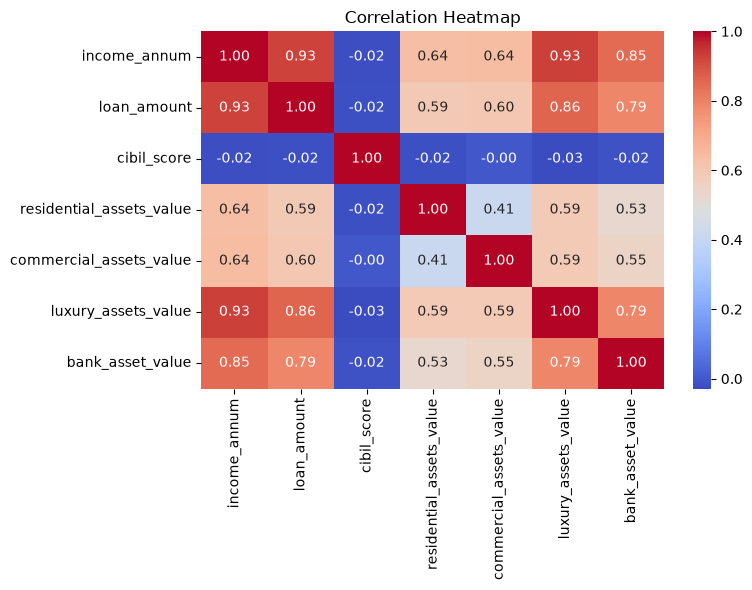

In [51]:
df=pd.read_csv('data/loan_approval_dataset.csv')
display(df.head())
df.columns=df.columns.str.strip() # To remove the extra spaces in the features.

print("DATA SUMMARY..")
numeric_columns=df[["income_annum",'loan_amount','cibil_score','residential_assets_value','commercial_assets_value','luxury_assets_value','bank_asset_value']]
print("MEAN..")
print(numeric_columns.mean())
print()
print("MEDIAN VALUES..")
print(numeric_columns.median())
print()
print("COVARIANCE..")
print(numeric_columns.cov())

# Correlation Heatmap 
plt.figure(figsize=(8,6))
sns.heatmap(numeric_columns.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


PREPROCESSING USING PIPELINES

In [52]:
# Check missing values
print(df.isnull().sum())
df=df.drop(columns=["loan_id"],errors="ignore")
df['education']=df['education'].str.strip()
df['self_employed']=df['self_employed'].str.strip()
numeric_features=["no_of_dependents","income_annum","cibil_score","residential_assets_value","commercial_assets_value","luxury_assets_value","bank_asset_value"]
categorical_features=["education","self_employed"]

loan_id                     0
no_of_dependents            0
education                   0
self_employed               0
income_annum                0
loan_amount                 0
loan_term                   0
cibil_score                 0
residential_assets_value    0
commercial_assets_value     0
luxury_assets_value         0
bank_asset_value            0
loan_status                 0
dtype: int64


In [53]:
numeric_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="median")),
        ("scaler",StandardScaler())
    ]
)
categorical_transformer=Pipeline(
    steps=[
        ("imputer",SimpleImputer(strategy="most_frequent")),
        ("onehot",OneHotEncoder(drop="first",handle_unknown="ignore")) 
    ]
)
preprocessor=ColumnTransformer(
    transformers=[
        ("numeric",numeric_transformer,numeric_features),
        ("categorical",categorical_transformer,categorical_features)
    ]
)

In [54]:
X=df.drop(columns=["loan_amount","loan_status"],errors="ignore")
y=df["loan_amount"]

In [55]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42)

In [56]:
model=Pipeline(
    steps=[
        ("preprocessor",preprocessor),
        ("regressor",LinearRegression())
    ]
)
model.fit(X_train,y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['no_of_dependents','education','self_employed',..., 'commercial_assets_value','luxury_assets_value','bank_asset_value']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `

In [57]:
y_train_pred = model.predict(X_train)
y_test_pred=model.predict(X_test)

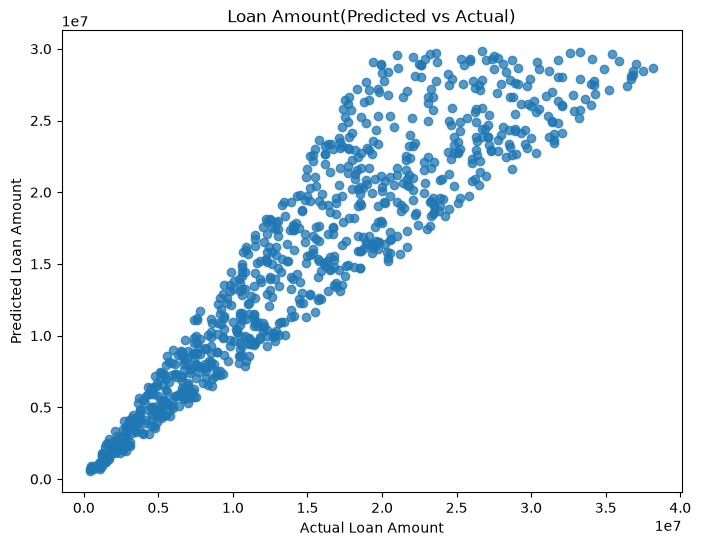

In [58]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_test_pred,alpha=0.75)
plt.xlabel("Actual Loan Amount")
plt.ylabel("Predicted Loan Amount")
plt.title("Loan Amount(Predicted vs Actual)")
plt.show()

Text(0.5, 0, 'Residual Errors')

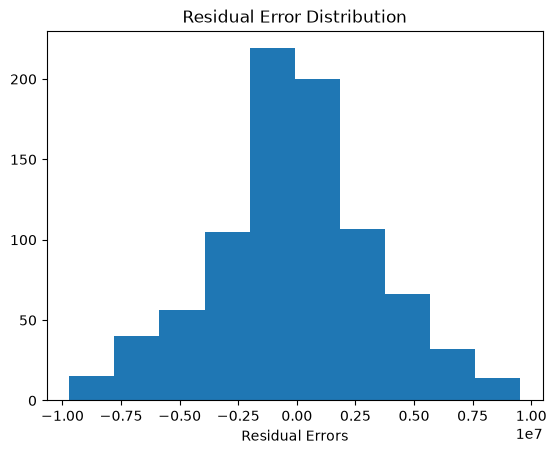

In [59]:
residual_error=y_test-y_test_pred
plt.hist(residual_error)
plt.title("Residual Error Distribution")
plt.xlabel("Residual Errors")